# 29. 결합 모델의 오류 분석 — 검사 예산 안에 든 불량과 밖에 남은 불량 (보고서 3·4장)
결합 = raw PVC(일별 개수 학습, 10시드 평균)와 D4(파생 5종 이탈 크기 합, 학습 없음)의 날짜 안 순위 평균. 새 학습은 하지 않고 저장된 점수만 쓴다.
1. Stellantis N.V. 전체 20일(날짜 하나 빼기), 예산 10%: 포착(TP)·미탐지(FN)·오경보(FP)·예산 밖 정상(TN)으로 나눠 조건 이탈과 위치를 비교한다.
2. 변수 간 상호작용: Stellantis N.V. 입열 × 가압력(실제 불량률), KAMP 전류 × 가압력(추천 비율), Querétaro 가압력 × 통전시간(너깃 미달).
3. 예산별 포착·미포착 표(날짜 하나 빼기, 시간순)와 KAMP 점검 기준 범위(추천이 드문 조건 구간).
동점은 정답을 쓰지 않고 파일 순서로 끊는다(포착 수는 기대값 처리와 같다).

In [1]:
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt, warnings
import br
from br import spec as S, plot as P
from wl.metrics import inclusion_prob, within_loc_auroc
from wl import data as wldata
warnings.filterwarnings("ignore"); P.setup(); pd.set_option("display.width", 240); pd.set_option("display.max_columns", 40)
if "Malgun Gothic" not in {f.name for f in mpl.font_manager.fontManager.ttflist}: mpl.rcParams["font.family"] = "Noto Sans CJK KR"
PAL, GRAY, INK, INK2 = P.PAL, P.GRAY, P.INK, P.INK2
X, day, cnt, y, _ = S.load_polito(); Xd, *_ = S.load_polito("derived5_absz")
P0 = wldata.load_polito(); loc = P0["loc"].values
RAW = pd.read_pickle(br.RES / "same_model_scores.pkl")
raw = np.mean([g.sort_values("row").score.values for _, g in RAW[(RAW.data == "polito") & (RAW.model == "PVC MLP")].groupby("seed")], 0)
d4 = Xd.sum(axis=1).values
rk = lambda s, g: pd.Series(s).groupby(g).rank(pct=True).values
comb = (rk(raw, day) + rk(d4, day)) / 2
ud, gi = np.unique(day, return_inverse=True); n = np.bincount(gi); pos = np.bincount(gi, weights=y)
caught = lambda s, b: (inclusion_prob(s, np.ceil(b * n - 1e-9), gi) * y).sum()

def pick(s, b):
    """날짜마다 상위 ceil(b·n)개. 동점은 파일 순서(정답 미사용)."""
    out = np.zeros(len(s), bool)
    for d in ud:
        ix = np.flatnonzero(day == d); k = int(np.ceil(b * len(ix) - 1e-9)); out[ix[np.argsort(-s[ix], kind="stable")[:k]]] = True
    return out

def rz(s, g):
    """날짜 안 강건 z(부호 유지): (값 − 그날 중앙값) / (1.4826·MAD)."""
    med = s.groupby(g).transform("median"); mad = (s - med).abs().groupby(g).transform("median") * 1.4826
    return ((s - med) / (mad + 1e-9 + 1e-6 * s.abs().groupby(g).transform("median"))).clip(-10, 10)

## 1. 예산 10%의 포착·미탐지·오경보

In [2]:
sel = pick(comb, .1)
df = pd.DataFrame(dict(day=day, loc=loc, y=y, sel=sel))
df["grp"] = np.select([(df.y == 1) & df.sel, (df.y == 1) & ~df.sel, (df.y == 0) & df.sel], ["포착", "미탐지", "오경보"], "예산 밖 정상")
NM = {"heat": "입열량", "cur": "전류", "time": "통전시간", "force": "가압력", "vol": "전압", "dynres": "동저항", "i_over_f": "전류/가압력"}
for c in X.columns: df["z_" + c] = rz(X[c], pd.Series(day)).values
zc = ["z_" + c for c in NM]
print(df.grp.value_counts().to_dict(), "| 검사", int(sel.sum()), "| 포착 기대값", round(caught(comb, .1), 1))
t1 = df.groupby("grp")[zc].median().round(2); t1.columns = list(NM.values()); t1.insert(0, "타점 수", df.grp.value_counts())
plain = (df[["z_" + c for c in X.columns]].abs().fillna(0) < 2).all(axis=1)      # 조건값 7개가 모두 그날 보통 범위(|강건 z| < 2)
t1["조건값이 모두 평범한 타점 수"] = plain.groupby(df.grp).sum(); t1["조건값이 모두 평범한 타점 비율"] = plain.groupby(df.grp).mean().round(3)
t1 = t1.loc[["포착", "미탐지", "오경보", "예산 밖 정상"]]; t1.to_csv(br.RES / "err_group_profile.csv", encoding="utf-8-sig"); display(t1)
bands = [(0, .05), (.05, .1), (.1, .2), (.2, .3), (.3, .5), (.5, 1.0)]
bv = [caught(comb, hi) - (caught(comb, lo) if lo > 0 else 0) for lo, hi in bands]
print("위험 순위 구간별 불량 수:", dict(zip(["상위 5%", "5~10%", "10~20%", "20~30%", "30~50%", "하위 50%"], np.round(bv, 1))))
print(f"같은 위치 안 AUROC: 결합 {within_loc_auroc(y, comb, loc):.3f}, raw {within_loc_auroc(y, raw, loc):.3f}, D4 {within_loc_auroc(y, d4, loc):.3f}")

{'예산 밖 정상': 1715, '오경보': 182, '미탐지': 55, '포착': 24} | 검사 206 | 포착 기대값 24.0


,타점 수,입열량,전류,통전시간,가압력,전압,동저항,전류/가압력,조건값이 모두 평범한 타점 수,조건값이 모두 평범한 타점 비율
grp,,,,,,,,,,
포착,24,2.29,2.26,2.06,0.56,0.65,-0.72,1.58,2,0.083
미탐지,55,1.00,0.34,0.68,0.47,0.67,0.42,0.73,26,0.473
오경보,182,1.96,2.24,1.55,0.87,0.44,-1.03,1.49,21,0.115
예산 밖 정상,1715,-0.07,-0.09,-0.01,-0.07,-0.08,0.07,-0.11,879,0.513


위험 순위 구간별 불량 수: {'상위 5%': np.float64(18.5), '5~10%': np.float64(5.5), '10~20%': np.float64(14.0), '20~30%': np.float64(12.0), '30~50%': np.float64(8.0), '하위 50%': np.float64(21.0)}
같은 위치 안 AUROC: 결합 0.516, raw 0.479, D4 0.525


## 2. 위치 그룹 — 예산이 쓰인 위치와 미탐지가 남은 위치

In [3]:
L = df.groupby("loc").agg(n=("y", "size"), pos=("y", "sum"), sel=("sel", "sum"), zh=("z_heat", "median")).assign(selrate=lambda d: d.sel / d.n)
lg = lambda l: "자주 추천(추천율>50%)" if L.selrate[l] > .5 else ("추천 안 됨(추천율≤5%)" if L.selrate[l] <= .05 else "가끔 추천")
df["lgrp"] = df["loc"].map(lg)
t2 = df.groupby("lgrp").agg(타점=("y", "size"), 불량=("y", "sum"), 포착=("grp", lambda s: (s == "포착").sum()), 미탐지=("grp", lambda s: (s == "미탐지").sum()),
                            오경보=("grp", lambda s: (s == "오경보").sum()), 입열이탈_중앙값=("z_heat", "median"), 전류이탈_중앙값=("z_cur", "median"))
t2.insert(0, "위치 수", df.drop_duplicates("loc").lgrp.value_counts()); t2["불량률%"] = (t2.불량 / t2.타점 * 100).round(1)
t2 = t2.loc[["자주 추천(추천율>50%)", "가끔 추천", "추천 안 됨(추천율≤5%)"]].round(2); t2.to_csv(br.RES / "err_location_groups.csv", encoding="utf-8-sig"); display(t2)
hot = df[df.lgrp.str.startswith("자주")]
print(f"자주 추천된 위치 안: 추천된 타점의 불량 비율 {hot[hot.sel].y.mean():.3f}, 그 위치 전체 불량률 {hot.y.mean():.3f}")
show = L.sort_values("pos", ascending=False).head(8).join(L[(L.pos == 0)].sort_values("sel", ascending=False).head(3), how="outer", rsuffix="_").iloc[:, :5]
display(L.loc[[84, 73, 60, 103, 10, 99, 101]].round(2))
small = df[df.day < "2023"]; print(f"2022년 날짜: {small.day.nunique()}일 {len(small)}타점, 불량 {int(small.y.sum())}건, 포착 {(small.grp=='포착').sum()}건")

,위치 수,타점,불량,포착,미탐지,오경보,입열이탈_중앙값,전류이탈_중앙값,불량률%
lgrp,,,,,,,,,
자주 추천(추천율>50%),15,233,32,21,11,146,2.01,2.19,13.7
가끔 추천,19,273,8,3,5,35,1.48,1.49,2.9
추천 안 됨(추천율≤5%),124,1470,39,0,39,1,-0.11,-0.18,2.7


자주 추천된 위치 안: 추천된 타점의 불량 비율 0.126, 그 위치 전체 불량률 0.137


,n,pos,sel,zh,selrate
loc,,,,,
84,16,13,0,1.67,0.00
73,19,12,13,2.96,0.68
60,14,5,0,1.97,0.00
103,17,4,10,2.95,0.59
10,15,3,11,2.33,0.73
99,16,0,14,1.12,0.88
101,17,0,15,3.58,0.88


2022년 날짜: 10일 136타점, 불량 7건, 포착 0건


## 3. 변수 간 상호작용

In [4]:
cut3 = lambda z: pd.cut(z, [-11, -.67, .67, 11], labels=["낮음", "보통", "높음"])
df["hz"], df["fz"] = cut3(df.z_heat), cut3(df.z_force)
i1 = df.dropna(subset=["fz"]).groupby(["hz", "fz"], observed=False).agg(타점=("y", "size"), 불량=("y", "sum")); i1["불량률%"] = (i1.불량 / i1.타점 * 100).round(1)
Zl = (X - X.groupby(pd.Series(loc)).transform("mean")) / X.groupby(pd.Series(loc)).transform("std")
df["lh"] = cut3(Zl.heat.clip(-10, 10))
i1b = df.dropna(subset=["lh"]).groupby("lh", observed=False).agg(타점=("y", "size"), 불량=("y", "sum")); i1b["불량률%"] = (i1b.불량 / i1b.타점 * 100).round(1)
print("Stellantis N.V. 입열 × 가압력 (그날 기준 수준)"); display(i1); print("Stellantis N.V. 같은 위치 안 입열 이탈"); display(i1b)
K = pd.read_csv(br.RES / "final_kamp_recommendations_combined.csv"); K = K[K["상태"] == "순위 부여"].copy()
K = K.rename(columns={"weld current(kA)": "cur", "weld force(bar)": "force", "weld time(ms)": "time", "추천_10%": "r10", "결합 등급": "grade"})
for c in ["cur", "force", "time"]: K["d_" + c] = K[c] - K.groupby("date")[c].transform("median")
K["cb"] = pd.cut(K.d_cur, [-9, -.10, -.05, .05, 9], labels=["0.10 이상 낮음", "0.05~0.10 낮음", "±0.05 이내", "0.05 넘게 높음"])
K["fb"] = pd.cut(K.d_force, [-9, -.03, .03, 9], labels=["0.03 넘게 낮음", "±0.03 이내", "0.03 넘게 높음"])
i2 = K.groupby(["cb", "fb"], observed=False).agg(타점=("r10", "size"), 추천율=("r10", "mean")); i2["추천율%"] = (i2.추천율 * 100).round(1)
print("KAMP 전류 × 가압력 (그날 중앙값 대비) 추천 상위 10% 비율"); display(i2[["타점", "추천율%"]])
Q = pd.read_csv(br.RES / "queretaro_samples.csv")
i3 = Q.groupby(["psi", "ms"]).agg(타점=("nug", "size"), 너깃미달=("undersize", "sum"), 날림=("expl", "sum")); i3["미달률%"] = (i3.너깃미달 / i3.타점 * 100).round(1)
print("Querétaro 가압력 × 통전시간"); display(i3)
i1.to_csv(br.RES / "err_interaction_polito.csv", encoding="utf-8-sig"); i2.to_csv(br.RES / "err_interaction_kamp.csv", encoding="utf-8-sig"); i3.to_csv(br.RES / "err_interaction_queretaro.csv", encoding="utf-8-sig")

Stellantis N.V. 입열 × 가압력 (그날 기준 수준)


타점  불량  불량률%
hz fz               
낮음 낮음   72   0   0.0
   보통   55   0   0.0
   높음  105   2   1.9
보통 낮음  137   2   1.5
   보통  345   7   2.0
   높음  318   7   2.2
높음 낮음   44   2   4.5
   보통  436  30   6.9
   높음  180  21  11.7

Stellantis N.V. 같은 위치 안 입열 이탈


,타점,불량,불량률%
lh,,,
낮음,454,23,5.1
보통,1068,48,4.5
높음,450,8,1.8


KAMP 전류 × 가압력 (그날 중앙값 대비) 추천 상위 10% 비율


타점  추천율%
cb           fb                    
0.10 이상 낮음   0.03 넘게 낮음    12  41.7
             ±0.03 이내     720  30.0
             0.03 넘게 높음  1401  36.1
0.05~0.10 낮음 0.03 넘게 낮음    12  16.7
             ±0.03 이내     498  17.1
             0.03 넘게 높음   142  19.7
±0.05 이내     0.03 넘게 낮음  1576   0.3
             ±0.03 이내    4340   3.7
             0.03 넘게 높음   405  12.1
0.05 넘게 높음   0.03 넘게 낮음   402   1.0
             ±0.03 이내     955   1.3
             0.03 넘게 높음   312   2.6

Querétaro 가압력 × 통전시간


타점  너깃미달  날림  미달률%
psi ms                      
60  400   99    18   6  18.2
    600   51     1   9   2.0
    800   50     1   5   2.0
    1000  72     0   0   0.0
    1200  60     3   4   5.0
80  600   50    11   1  22.0
    800   51    12   1  23.5
    1000  29     5   0  17.2

## 4. 예산별 포착·미포착 (날짜 하나 빼기, 시간순)

In [5]:
E3 = pd.read_pickle(br.RES / "exp3_scores.pkl")
TE = np.array([d_ >= "2024-02-01" for d_ in day]); yt, dt = y[TE], day[TE]
comb_t = (rk(E3["raw_temporal"], dt) + rk(d4[TE], dt)) / 2
_, git = np.unique(dt, return_inverse=True); nt = np.bincount(git); post = np.bincount(git, weights=yt)
ct = lambda s, b: (inclusion_prob(s, np.ceil(b * nt - 1e-9), git) * yt).sum()
rows = []
for b in (.05, .1, .2, .3, .4, .5, .6, .7, .8, .9):
    k, kt = np.ceil(b * n - 1e-9), np.ceil(b * nt - 1e-9); h, ht = caught(comb, b), ct(comb_t, b)
    rows.append({"예산%": int(b * 100), "검사 수": int(k.sum()), "포착": round(h, 1), "미포착": round(79 - h, 1), "포착률%": round(h / 79 * 100, 1), "무작위": round((k / n * pos).sum(), 1),
                 "시간순 검사 수": int(kt.sum()), "시간순 포착": round(ht, 1), "시간순 미포착": round(51 - ht, 1), "시간순 포착률%": round(ht / 51 * 100, 1), "시간순 무작위": round((kt / nt * post).sum(), 1)})
t4 = pd.DataFrame(rows); t4.to_csv(br.RES / "err_budget_table.csv", index=False, encoding="utf-8-sig"); display(t4)

,예산%,검사 수,포착,미포착,포착률%,무작위,시간순 검사 수,시간순 포착,시간순 미포착,시간순 포착률%,시간순 무작위
0,5,109,18.5,60.5,23.4,4.9,49,9.0,42.0,17.6,3.4
1,10,206,24.0,55.0,30.4,8.6,95,17.0,34.0,33.3,5.7
2,20,403,38.0,41.0,48.1,16.0,188,21.0,30.0,41.2,10.3
3,30,601,50.0,29.0,63.3,24.4,281,25.0,26.0,49.0,15.8
4,40,799,51.0,28.0,64.6,31.8,374,26.0,25.0,51.0,20.5
5,50,994,58.0,21.0,73.4,40.1,466,36.0,15.0,70.6,26.0
6,60,1193,62.0,17.0,78.5,47.6,560,43.0,8.0,84.3,30.7
7,70,1393,69.5,9.5,88.0,56.1,654,47.0,4.0,92.2,36.3
8,80,1589,73.0,6.0,92.4,63.5,746,49.0,2.0,96.1,40.8
9,90,1788,76.0,3.0,96.2,71.9,840,51.0,0.0,100.0,46.5


## 5. KAMP 점검 기준 범위 — 결합 추천이 드문 조건 구간
모델이 고른 타점의 특성으로 정한 범위다. 불량률로 검증한 범위가 아니다.

In [6]:
w = (K.d_cur > -.05) & (K.d_force <= .03); ab = K.grade != "C"
print(f"범위(전류 > 그날 중앙값 −0.05kA, 가압력 ≤ +0.03bar) 안 타점 {w.mean():.3f} | 추천율 안 {K[w].r10.mean():.3f}, 밖 {K[~w].r10.mean():.3f} | "
      f"상위 10% 추천 중 범위 밖 {1-(w&K.r10).sum()/K.r10.sum():.3f} | A·B등급 {int(ab.sum())}개 중 범위 밖 {1-(w&ab).sum()/ab.sum():.3f}")
print(K.groupby("date")[["cur", "force", "time"]].median().agg(["min", "max"]))
binsets = [("d_cur", [-9, -.2, -.15, -.1, -.05, 0, .05, .1, 9]), ("d_force", [-9, -.06, -.03, 0, .03, .06, 9]), ("d_time", [-9, -1.5, -.5, .5, 9])]
W = {c: K.groupby(pd.cut(K[c], b), observed=True).agg(타점=("r10", "size"), 추천율=("r10", "mean")) for c, b in binsets}
pd.concat(W).to_csv(br.RES / "err_kamp_window.csv", encoding="utf-8-sig"); [display(v.round(3)) for v in W.values()]

범위(전류 > 그날 중앙값 −0.05kA, 가압력 ≤ +0.03bar) 안 타점 0.675 | 추천율 안 0.025, 밖 0.257 | 상위 10% 추천 중 범위 밖 0.833 | A·B등급 225개 중 범위 밖 0.853
       cur  force  time
min  14.61   2.31  72.0
max  14.75   2.35  72.0


,타점,추천율
d_cur,,
"(-9.0, -0.2]",76,0.500
"(-0.2, -0.15]",809,0.393
"(-0.15, -0.1]",1248,0.297
"(-0.1, -0.05]",652,0.176
"(-0.05, 0.0]",3286,0.062
"(0.0, 0.05]",3035,0.003
"(0.05, 0.1]",782,0.022
"(0.1, 9.0]",887,0.008


,타점,추천율
d_force,,
"(-9.0, -0.06]",258,0.008
"(-0.06, -0.03]",1744,0.007
"(-0.03, 0.0]",4068,0.044
"(0.0, 0.03]",2445,0.120
"(0.03, 0.06]",1376,0.281
"(0.06, 9.0]",884,0.232


,타점,추천율
d_time,,
"(-9.0, -1.5]",234,0.226
"(-1.5, -0.5]",3363,0.133
"(-0.5, 0.5]",6363,0.085
"(0.5, 9.0]",815,0.048


[None, None, None]

## 6. 그림
보고서 본문 폭(약 162mm = 6.4인치)에 맞춰 그린다. 그림을 줄여 넣지 않으므로 글자가 본문(10pt)과 비슷한 크기로 보인다. 한 그림에 한 가지만 담는다.

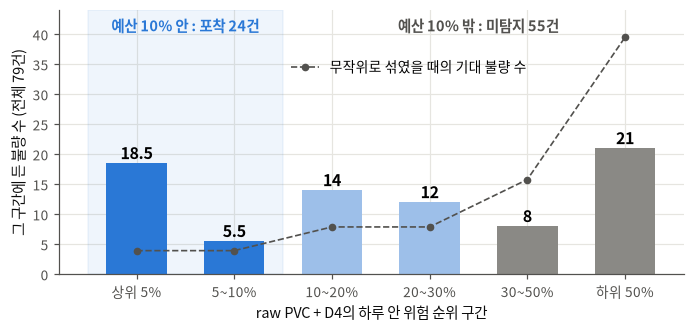

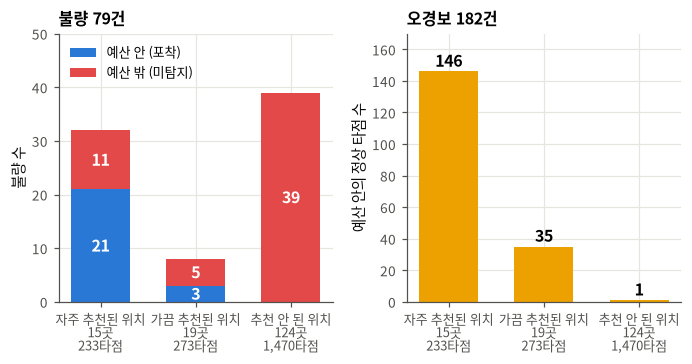

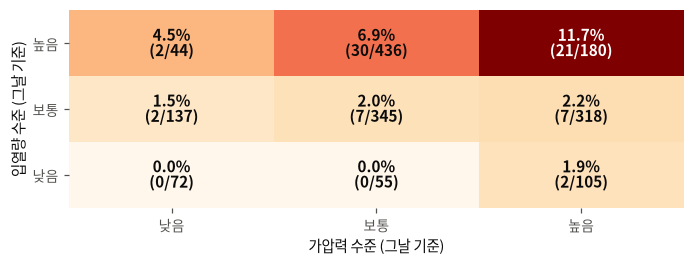

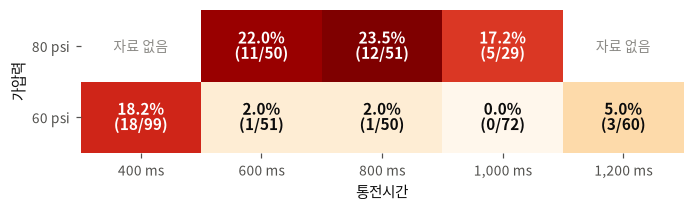

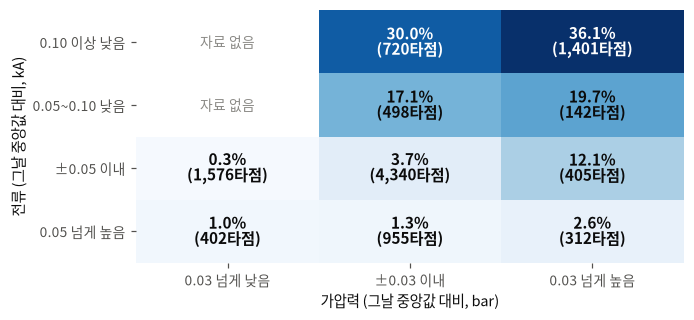

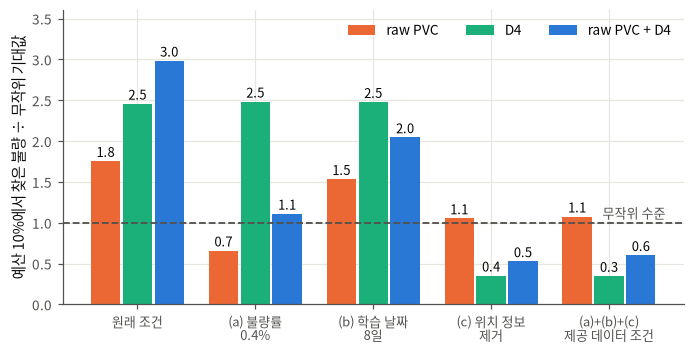

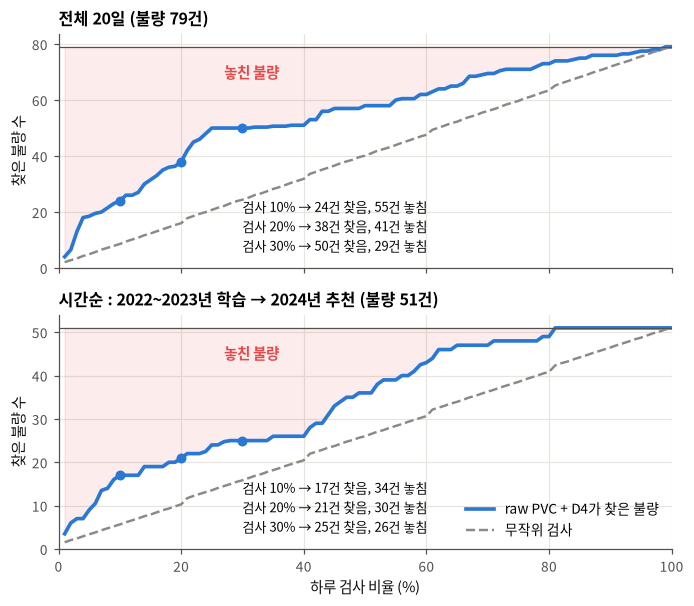

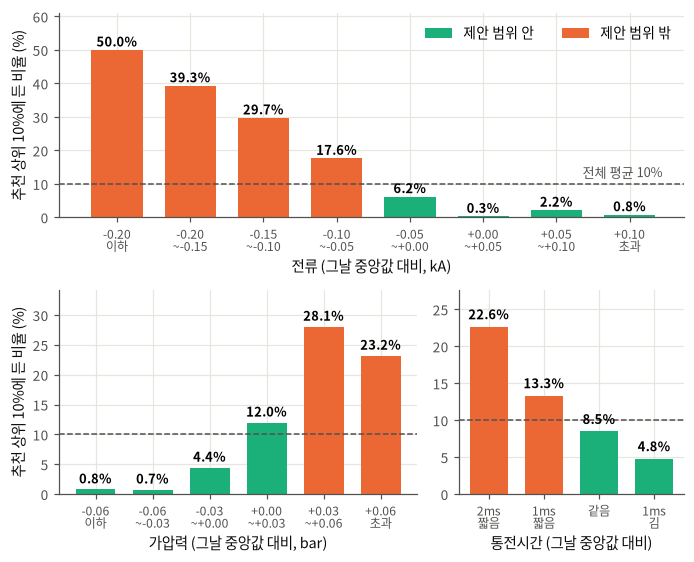

,변수,집단,낮음,높음
0,전류,추천 상위 10%,95.0,3.0
1,전류,나머지 타점,42.0,48.0
2,입열량,추천 상위 10%,85.0,15.0
3,입열량,나머지 타점,46.0,54.0
4,가압력,추천 상위 10%,10.0,82.0
5,가압력,나머지 타점,46.0,39.0
6,통전시간,추천 상위 10%,46.0,8.0
7,통전시간,나머지 타점,32.0,11.0
8,전류÷가압력,추천 상위 10%,92.0,8.0
9,전류÷가압력,나머지 타점,44.0,54.0


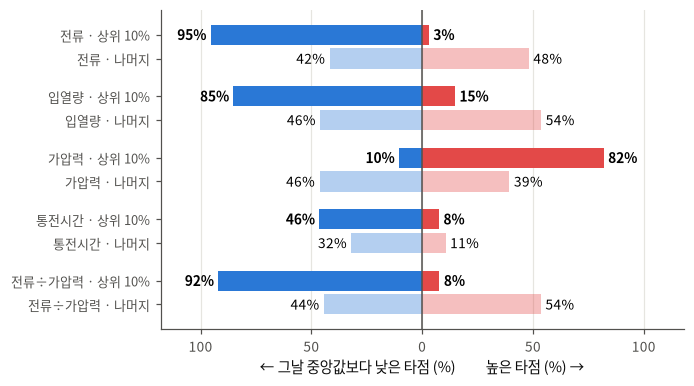

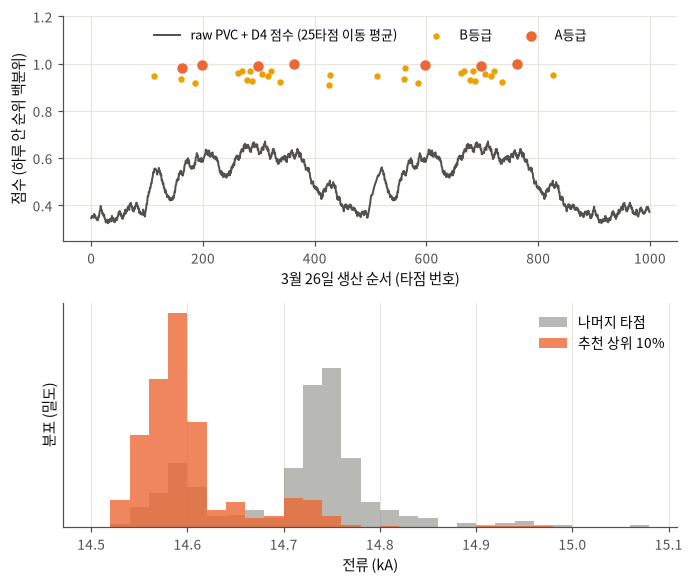

In [7]:
Wd = 6.4
mpl.rcParams.update({"font.size": 9.5, "axes.titlesize": 10.5, "axes.labelsize": 9.5, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9, "savefig.dpi": 300})
def heat(ax, M, rl, cl, xl, yl, cnt, cmap):
    vmax = np.nanmax(M); ax.imshow(M, cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if np.isnan(M[i, j]): ax.text(j, i, "자료 없음", ha="center", va="center", fontsize=9, color=GRAY); continue
            ax.text(j, i, f"{M[i,j]:.1f}%\n({cnt[i][j]})", ha="center", va="center", fontsize=10, color="white" if M[i, j] > .6 * vmax else INK, fontweight="bold")
    ax.set_xticks(range(len(cl))); ax.set_xticklabels(cl); ax.set_yticks(range(len(rl))); ax.set_yticklabels(rl)
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.grid(False)
    for s_ in ax.spines.values(): s_.set_visible(False)

# 그림 25: 위험 순위 구간별 불량
fig, ax = plt.subplots(figsize=(Wd, 3.1)); x = np.arange(6); lab = ["상위 5%", "5~10%", "10~20%", "20~30%", "30~50%", "하위 50%"]
ax.bar(x, bv, color=[PAL[0], PAL[0], "#9dbfe9", "#9dbfe9", GRAY, GRAY], width=.62)
ax.plot(x, [(hi - lo) * 79 for lo, hi in bands], "o--", color=INK2, lw=1.1, ms=4, label="무작위로 섞였을 때의 기대 불량 수")
for xi, v in zip(x, bv): ax.text(xi, v + .7, f"{v:.1f}".rstrip("0").rstrip("."), ha="center", fontsize=10.5, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(lab); ax.set_ylabel("그 구간에 든 불량 수 (전체 79건)"); ax.set_xlabel("raw PVC + D4의 하루 안 위험 순위 구간"); ax.set_ylim(0, 44)
ax.axvspan(-.5, 1.5, color=PAL[0], alpha=.07); ax.text(.5, 40.5, "예산 10% 안 : 포착 24건", ha="center", color=PAL[0], fontsize=9.5, fontweight="bold")
ax.text(3.5, 40.5, "예산 10% 밖 : 미탐지 55건", ha="center", color=INK2, fontsize=9.5, fontweight="bold"); ax.legend(loc="upper center", bbox_to_anchor=(.56, .86))
fig.tight_layout(); P.save(fig, "25_rank_bands"); plt.show()

# 그림 26: 위치 그룹 (불량의 행방, 오경보)
o = list(t2.index); xx = np.arange(3)
names = [f"{a_}\n{t2['위치 수'][g_]}곳\n{t2.타점[g_]:,}타점" for a_, g_ in zip(["자주 추천된 위치", "가끔 추천된 위치", "추천 안 된 위치"], o)]
fig, axes = plt.subplots(1, 2, figsize=(Wd, 3.4))
ax = axes[0]; ax.bar(xx, t2.포착, color=PAL[0], width=.62, label="예산 안 (포착)"); ax.bar(xx, t2.미탐지, bottom=t2.포착, color=PAL[7], width=.62, label="예산 밖 (미탐지)")
for i, g_ in enumerate(o):
    if t2.포착[g_] > 0: ax.text(i, t2.포착[g_] / 2, int(t2.포착[g_]), ha="center", va="center", color="white", fontweight="bold", fontsize=10.5)
    ax.text(i, t2.포착[g_] + t2.미탐지[g_] / 2, int(t2.미탐지[g_]), ha="center", va="center", color="white", fontweight="bold", fontsize=10.5)
ax.set_ylabel("불량 수"); ax.set_ylim(0, 50); ax.legend(loc="upper left", fontsize=8.5); ax.set_title("불량 79건", loc="left", fontweight="bold")
ax = axes[1]; ax.bar(xx, t2.오경보, color=PAL[3], width=.62)
for i, g_ in enumerate(o): ax.text(i, t2.오경보[g_] + 3, int(t2.오경보[g_]), ha="center", fontweight="bold", fontsize=10.5)
ax.set_ylabel("예산 안의 정상 타점 수"); ax.set_ylim(0, 170); ax.set_title(f"오경보 {int(t2.오경보.sum())}건", loc="left", fontweight="bold")
for ax in axes: ax.set_xticks(xx); ax.set_xticklabels(names, fontsize=8.5)
fig.tight_layout(); P.save(fig, "26_location_groups"); plt.show()

# 그림 27a·b·c: 상호작용 (데이터별로 한 장씩)
lv = ["낮음", "보통", "높음"]
M = i1["불량률%"].unstack().values; C = [[f"{int(i1.불량[(h,f)])}/{int(i1.타점[(h,f)])}" for f in lv] for h in lv]
fig, ax = plt.subplots(figsize=(Wd, 2.5)); heat(ax, M[::-1], lv[::-1], lv, "가압력 수준 (그날 기준)", "입열량 수준 (그날 기준)", C[::-1], "OrRd")
fig.tight_layout(); P.save(fig, "27a_interaction_stellantis"); plt.show()
ms = [400, 600, 800, 1000, 1200]; M3 = np.full((2, 5), np.nan); C3 = [[""] * 5 for _ in range(2)]
for i, p in enumerate([80, 60]):
    for j, m in enumerate(ms):
        if (p, m) in i3.index: M3[i, j] = i3["미달률%"][(p, m)]; C3[i][j] = f"{int(i3.너깃미달[(p,m)])}/{int(i3.타점[(p,m)])}"
fig, ax = plt.subplots(figsize=(Wd, 2.0)); heat(ax, M3, ["80 psi", "60 psi"], [f"{m:,} ms" for m in ms], "통전시간", "가압력", C3, "OrRd")
fig.tight_layout(); P.save(fig, "27b_interaction_queretaro"); plt.show()
n2 = i2.타점.unstack().values; M2 = np.where(n2 < 30, np.nan, i2["추천율%"].unstack().values)
fig, ax = plt.subplots(figsize=(Wd, 3.0)); heat(ax, M2, list(i2.타점.unstack().index), list(i2.타점.unstack().columns), "가압력 (그날 중앙값 대비, bar)", "전류 (그날 중앙값 대비, kA)", [[f"{int(v):,}타점" for v in r] for r in n2], "Blues")
fig.tight_layout(); P.save(fig, "27c_interaction_kamp"); plt.show()

# 그림 28: 제공 데이터 조건 재현 (24번 노트북 결과표를 보고서 표기로 다시 그림)
E = pd.read_csv(br.RES / "exp2_conditions.csv")
conds = [("base", "원래 조건"), ("a", "(a) 불량률\n0.4%"), ("b", "(b) 학습 날짜\n8일"), ("c1", "(c) 위치 정보\n제거"), ("abc", "(a)+(b)+(c)\n제공 데이터 조건")]
fig, ax = plt.subplots(figsize=(Wd, 3.3)); wd = .27
for k_, (m, nm, col) in enumerate([("raw PVC", "raw PVC", PAL[1]), ("D4", "D4", PAL[2]), ("결합", "raw PVC + D4", PAL[0])]):
    v = [np.divide(*map(float, E[(E["조건"] == c) & (E["모델"] == m)]["10% 포착/무작위"].iloc[0].split("/"))) for c, _ in conds]
    ax.bar(np.arange(5) + (k_ - 1) * wd, v, wd * .92, color=col, label=nm)
    for i, vv in enumerate(v): ax.text(i + (k_ - 1) * wd, vv + .05, f"{vv:.1f}", ha="center", fontsize=8.5)
ax.axhline(1, color=INK2, ls="--", lw=1.2); ax.text(4.48, 1.06, "무작위 수준", ha="right", color=INK2, fontsize=8.5)
ax.set_xticks(range(5)); ax.set_xticklabels([c[1] for c in conds], fontsize=8.5); ax.set_ylabel("예산 10%에서 찾은 불량 ÷ 무작위 기대값"); ax.set_ylim(0, 3.6); ax.legend(ncol=3, loc="upper right")
fig.tight_layout(); P.save(fig, "28_conditions_report"); plt.show()

# 그림 29: 예산 곡선 (위아래 두 칸)
bb = np.round(np.arange(.01, 1.001, .01), 2)
fig, axes = plt.subplots(2, 1, figsize=(Wd, 5.6), sharex=True)
for ax, (nm, cf, rf, tot, off) in zip(axes, [("전체 20일 (불량 79건)", lambda b: caught(comb, b), lambda b: (np.ceil(b * n - 1e-9) / n * pos).sum(), 79, ((9, -.15), (10, -.16), (10, -.15))),
                                              ("시간순 : 2022~2023년 학습 → 2024년 추천 (불량 51건)", lambda b: ct(comb_t, b), lambda b: (np.ceil(b * nt - 1e-9) / nt * post).sum(), 51, ((5, .36), (12, .38), (12, -.29)))]):
    c = [cf(b) for b in bb]
    ax.fill_between(bb * 100, c, tot, color=PAL[7], alpha=.10); ax.plot(bb * 100, c, color=PAL[0], lw=2.4, label="raw PVC + D4가 찾은 불량"); ax.plot(bb * 100, [rf(b) for b in bb], "--", color=GRAY, lw=1.6, label="무작위 검사")
    ax.axhline(tot, color=INK2, lw=.8)
    pts = [(b, cf(b / 100)) for b in (10, 20, 30)]
    ax.plot([p[0] for p in pts], [p[1] for p in pts], "o", color=PAL[0], ms=5.5)
    ax.text(.30, .05, "\n".join(f"검사 {b}% → {v:.0f}건 찾음, {tot-v:.0f}건 놓침" for b, v in pts), transform=ax.transAxes, fontsize=8.5, va="bottom", linespacing=1.5)
    ax.text(27, tot * .86, "놓친 불량", color=PAL[7], fontsize=9.5, fontweight="bold")
    ax.set_xlim(0, 100); ax.set_ylim(0, tot * 1.06); ax.set_ylabel("찾은 불량 수"); ax.set_title(nm, loc="left", fontweight="bold")
axes[1].set_xlabel("하루 검사 비율 (%)"); axes[1].legend(loc="lower right")
fig.tight_layout(); P.save(fig, "29_budget_curve_report"); plt.show()

# 그림 30: 제공 데이터 점검 기준 범위 (위: 전류, 아래: 가압력·통전시간)
fig = plt.figure(figsize=(Wd, 5.2)); gs = fig.add_gridspec(2, 5)
for ax, (col, xl, lim, side) in zip([fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, :3]), fig.add_subplot(gs[1, 3:])],
                                    [("d_cur", "전류 (그날 중앙값 대비, kA)", -.05, "lo"), ("d_force", "가압력 (그날 중앙값 대비, bar)", .03, "hi"), ("d_time", "통전시간 (그날 중앙값 대비)", -.5, "lo")]):
    a = W[col]
    lab = ["2ms\n짧음", "1ms\n짧음", "같음", "1ms\n김"] if col == "d_time" else [f"{iv.right:+.2f}\n이하" if iv.left < -5 else (f"{iv.left:+.2f}\n초과" if iv.right > 5 else f"{iv.left:+.2f}\n~{iv.right:+.2f}") for iv in a.index]
    good = [(iv.left >= lim - 1e-9) if side == "lo" else (iv.right <= lim + 1e-9) for iv in a.index]
    ax.bar(range(len(a)), a.추천율 * 100, color=[PAL[2] if g_ else PAL[1] for g_ in good], width=.7)
    for i, v in enumerate(a.추천율 * 100): ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=8.5, fontweight="bold")
    ax.axhline(10, color=INK2, ls="--", lw=1); ax.set_xticks(range(len(a))); ax.set_xticklabels(lab, fontsize=8); ax.set_xlabel(xl); ax.set_ylim(0, max(a.추천율 * 100) * 1.22); ax.set_ylabel("추천 상위 10%에 든 비율 (%)" if col != "d_time" else "")
    if col == "d_cur": ax.text(7.45, 12, "전체 평균 10%", ha="right", fontsize=8.5, color=INK2); ax.bar([0], [0], color=PAL[2], label="제안 범위 안"); ax.bar([0], [0], color=PAL[1], label="제안 범위 밖"); ax.legend(loc="upper right", ncol=2)
fig.tight_layout(); P.save(fig, "30_kamp_window"); plt.show()

# 그림 31: 제공 데이터 추천 타점의 이탈 방향 (상위 10%와 나머지, 그날 중앙값 대비)
K["heat"] = K.cur * K["weld Voltage(v)"] * K.time; K["iof"] = K.cur / K.force
for c in ["heat", "iof"]: K["d_" + c] = K[c] - K.groupby("date")[c].transform("median")
rows = []
for c, nm in [("d_cur", "전류"), ("d_heat", "입열량"), ("d_force", "가압력"), ("d_time", "통전시간"), ("d_iof", "전류÷가압력")]:
    for g_, m in [("추천 상위 10%", K.r10), ("나머지 타점", ~K.r10)]:
        rows.append(dict(변수=nm, 집단=g_, 낮음=(K[m][c] < -1e-12).mean() * 100, 높음=(K[m][c] > 1e-12).mean() * 100))
D = pd.DataFrame(rows); D.round(1).to_csv(br.RES / "err_kamp_direction.csv", index=False, encoding="utf-8-sig"); display(D.round(0))
fig, ax = plt.subplots(figsize=(Wd, 3.6)); yy = []
for i, r in D.iterrows():
    y0 = -(i // 2) * 2.6 - (i % 2) * 1.0; yy.append(y0); top = r.집단.startswith("추천")
    ax.barh(y0, -r.낮음, color=PAL[0], alpha=1 if top else .35, height=.85); ax.barh(y0, r.높음, color=PAL[7], alpha=1 if top else .35, height=.85)
    ax.text(-r.낮음 - 2, y0, f"{r.낮음:.0f}%", ha="right", va="center", fontsize=9, fontweight="bold" if top else "normal")
    ax.text(r.높음 + 2, y0, f"{r.높음:.0f}%", ha="left", va="center", fontsize=9, fontweight="bold" if top else "normal")
ax.set_yticks(yy); ax.set_yticklabels([f"{r.변수} · {'상위 10%' if r.집단.startswith('추천') else '나머지'}" for _, r in D.iterrows()], fontsize=8.5)
ax.axvline(0, color=INK2, lw=1); ax.set_xlim(-118, 118); ax.set_xticks([-100, -50, 0, 50, 100]); ax.set_xticklabels(["100", "50", "0", "50", "100"])
ax.set_xlabel("← 그날 중앙값보다 낮은 타점 (%)          높은 타점 (%) →"); ax.grid(axis="y", visible=False)
fig.tight_layout(); P.save(fig, "31_kamp_direction_report"); plt.show()

# 그림 32: 제공 데이터 적용 예시 (위: 하루 생산 순서 위의 추천 위치, 아래: 추천 타점의 전류 분포)
d0 = "2020-03-26"; k0 = K[K.date == d0].sort_values("idx").reset_index(drop=True); sc = k0["결합점수"]
fig, axes = plt.subplots(2, 1, figsize=(Wd, 5.4))
ax = axes[0]; ax.plot(k0.index, sc.rolling(25, center=True, min_periods=5).mean(), color=INK2, lw=1.3, label="raw PVC + D4 점수 (25타점 이동 평균)")
b_, a_ = k0.grade == "B", k0.grade == "A"
ax.scatter(k0.index[b_], sc[b_], s=10, color=PAL[3], label="B등급", zorder=3); ax.scatter(k0.index[a_], sc[a_], s=34, color=PAL[1], label="A등급", zorder=4)
ax.set_xlabel("3월 26일 생산 순서 (타점 번호)"); ax.set_ylabel("점수 (하루 안 순위 백분위)"); ax.set_ylim(.25, 1.2); ax.legend(loc="upper center", ncol=3, fontsize=8.5)
ax = axes[1]; bins = np.arange(14.5, 15.1, .02)
ax.hist(K[~K.r10].cur, bins=bins, color=GRAY, alpha=.6, density=True, label="나머지 타점"); ax.hist(K[K.r10].cur, bins=bins, color=PAL[1], alpha=.8, density=True, label="추천 상위 10%")
ax.set_xlabel("전류 (kA)"); ax.set_ylabel("분포 (밀도)"); ax.set_yticks([]); ax.legend(loc="upper right")
fig.tight_layout(); P.save(fig, "32_kamp_recommend_report"); plt.show()